<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/MUFSAL_EfficientNetB5_full.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MUFSAL - EfficientNet-B5 (KL 0-4): old vs new preprocessing, 3 seeds, ensemble

**How to run**
1. Runtime > Change runtime type > **T4 GPU**.
2. First run with `SMOKE_TEST = True` (next cell) and press *Run all*. It uses a tiny subset (about 5-10 minutes) and only checks that nothing crashes. **Its numbers are meaningless.**
3. Then set `SMOKE_TEST = False` and *Restart session and run all* (about 1 hour for 2 pipelines x 3 seeds).

**What is inside**
- `old` pipeline = CLAHE + resize 224x224 (what we trained so far).
- `new` pipeline = standardization (brightness/contrast) + joint-aware crop 224x104.
- Same training recipe as before (Phase 1 frozen head, Phase 2 fine-tuning), repeated for every seed.
- Results: per seed, mean +/- std, seed ensemble, and the progressive grade elimination decoding.


In [1]:
# ===================== SETTINGS (the only cell you normally edit) =====================
SMOKE_TEST = False            # True = tiny quick run to check the code works (results are NOT real)
PIPELINES  = ["old", "new"]    # "old" = CLAHE + resize 224x224 | "new" = standardization + joint crop 224x104
SEEDS      = [42, 123, 2024]   # one full training run per seed and per pipeline
RUN_VERIFY = True              # check every standardized image (about 3 min). Set False after you reviewed it
USE_DRIVE  = False             # True = save results in Google Drive (they survive a Colab disconnect)

EPOCHS1    = 3                 # Phase 1: frozen backbone (same as before)
EPOCHS2    = 20                # Phase 2: fine-tuning (same as before, early stopping patience 5)
BATCH_SIZE = 32                # if CUDA out-of-memory -> 16
IMG_SIZE   = 224

if SMOKE_TEST:
    SEEDS, EPOCHS1, EPOCHS2 = SEEDS[:1], 1, 1
    SMOKE_N = {"train": 30, "val": 10, "test": 10}      # images per class in the quick test
    print("SMOKE TEST is ON: tiny subset, 1 seed, 1+1 epochs. Do not use these results.")
SAVE_DIR = "/content/runs_smoke" if SMOKE_TEST else "/content/runs"


In [2]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)


Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [3]:
import os, re, copy, time, random, gc, hashlib
from collections import Counter
import numpy as np, pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

import torch
import torch.nn as nn
import torch.optim as optim
import torch.backends.cudnn as cudnn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, datasets, models
from sklearn.metrics import cohen_kappa_score, f1_score, classification_report, confusion_matrix

cudnn.benchmark = True   # hey GPU find the most optimized way to run

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", device, "|", torch.cuda.get_device_name(0) if device == 'cuda' else "NO GPU")
if device != 'cuda':
    raise RuntimeError("GPU is OFF -> Runtime > Change runtime type > T4 GPU, then Runtime > Run all.")

NUM_WORKERS = min(4, os.cpu_count() or 2)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/mufsal_runs" + ("_smoke" if SMOKE_TEST else "")
os.makedirs(SAVE_DIR, exist_ok=True)
print("results are saved in:", SAVE_DIR)


device: cuda | Tesla T4
results are saved in: /content/runs


## Data (same code as before)


In [4]:
from torchvision import transforms, datasets
import os, re

# ---- find the folder that contains train / val / test (works whatever the nesting is) ----
def find_base(root):
    for dp, dn, _ in os.walk(root):
        if {"train", "val", "test"} <= set(dn):
            return dp
    raise FileNotFoundError("train/val/test folders not found under " + root)

base = find_base(path)
print("base:", base)          # NOTE: 'auto_test' (if it exists) is NOT used

# ---- choose the task ----------------------------------------------------------------------
# "5class" : KL 0,1,2,3,4 (normal 5-class task)
# "merge01": KL 0+1 merged -> 4 classes  (0-1 | 2 | 3 | 4)
# "binary" : KL 0+1 vs KL>=2 (clinically relevant OA yes/no)
# "drop01" : REMOVE KL 0 and 1 completely -> 3 classes (2 | 3 | 4)  (different, easier task!)
MODE = "5class"   # all grades KL0-KL4

MODES = {
    "5class":  ({0: 0, 1: 1, 2: 2, 3: 3, 4: 4},          ["KL0", "KL1", "KL2", "KL3", "KL4"]),
    "merge01": ({0: 0, 1: 0, 2: 1, 3: 2, 4: 3},          ["KL0-1", "KL2", "KL3", "KL4"]),
    "binary":  ({0: 0, 1: 0, 2: 1, 3: 1, 4: 1},          ["KL0-1", "KL2-4"]),
    "drop01":  ({0: None, 1: None, 2: 0, 3: 1, 4: 2},    ["KL2", "KL3", "KL4"]),
}
LABEL_MAP, CLASS_NAMES = MODES[MODE]
NUM_CLASSES = len(CLASS_NAMES)

def remap(ds):
    """Re-label (or drop) samples of a freshly loaded ImageFolder according to MODE."""
    folder_names = ds.classes                       # e.g. ['0','1','2','3','4']
    samples = []
    for p, c in ds.samples:
        grade = int(re.match(r"\d", folder_names[c]).group())   # KL grade from the folder name
        new = LABEL_MAP[grade]
        if new is not None:
            samples.append((p, new))
    ds.samples = ds.imgs = samples
    ds.targets = [t for _, t in samples]
    ds.classes = CLASS_NAMES
    ds.class_to_idx = {n: i for i, n in enumerate(CLASS_NAMES)}

# Resolution. (If the check below prints 224x224, 224 is the fastest option.)
IMG_SIZE = 224   # fastest. (300 = ~2x slower, only worth it if accuracy is still low)

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)
print("folders found:", train.classes)
for ds in (train, val, test):
    remap(ds)

from PIL import Image
print("original image size:", Image.open(train.samples[0][0]).size)
print("MODE:", MODE, "| classes:", train.classes)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


base: /kaggle/input/knee-osteoarthritis-dataset-with-severity
folders found: ['0', '1', '2', '3', '4']
original image size: (224, 224)
MODE: 5class | classes: ['KL0', 'KL1', 'KL2', 'KL3', 'KL4']
train: 5778 | val: 826 | test: 1656


In [5]:
def shrink(ds, n_per_class):
    """Keep only the first n images of every class (used by the quick test only)."""
    seen, keep = Counter(), []
    for p, y in ds.samples:
        if seen[y] < n_per_class:
            keep.append((p, y)); seen[y] += 1
    ds.samples = ds.imgs = keep
    ds.targets = [y for _, y in keep]

if SMOKE_TEST:
    for name, ds in [("train", train), ("val", val), ("test", test)]:
        shrink(ds, SMOKE_N[name])
    print("SMOKE TEST subset -> train:", len(train), "| val:", len(val), "| test:", len(test))


In [6]:
# Leakage check: are there byte-identical images shared between splits?
import hashlib

def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

H = {n: {md5(p) for p, _ in ds.samples} for n, ds in [("train", train), ("val", val), ("test", test)]}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a} & {b}: {len(H[a] & H[b])} identical images")
# 0 means no exact duplicates (near-duplicates / same patient can still exist)


train & val: 0 identical images
train & test: 0 identical images
val & test: 0 identical images


In [7]:
# class counts and class weights (same as before)
for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (NUM_CLASSES * counts[i]) for i in range(NUM_CLASSES)]
class_weights = torch.tensor(weights, dtype=torch.float)
print("class weights:", [round(w, 2) for w in weights])

# loss: weighted cross-entropy + label smoothing (same as before)
loss_fn = nn.CrossEntropyLoss(weight=class_weights.float().to(device), label_smoothing=0.1)


train {'KL0': 2286, 'KL1': 1046, 'KL2': 1516, 'KL3': 757, 'KL4': 173}
val {'KL0': 328, 'KL1': 153, 'KL2': 212, 'KL3': 106, 'KL4': 27}
test {'KL0': 639, 'KL1': 296, 'KL2': 447, 'KL3': 223, 'KL4': 51}
class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


## Preprocessing - OLD (what we trained so far): CLAHE + resize


In [8]:
# CLAHE contrast enhancement (blur optional, off by default) - same as before
class Denoise:
    def __init__(self, blur=False):
        self.blur = blur
    def __call__(self, img):
        g = np.array(img.convert("L"))
        if self.blur:
            g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
        return Image.fromarray(g)

pre_old = transforms.Compose([Denoise(), transforms.Resize((IMG_SIZE, IMG_SIZE))])   # 224 x 224


## Preprocessing - NEW: standardization + joint-aware crop
1. Same brightness and contrast for every image (percentile stretch + CLAHE + gamma curve, nothing is clipped).
2. The code looks for the joint gap (the dark band between the two bones) and crops 104 rows around it (shift limited to +/-16 px).
3. If the joint is not found with confidence, the crop stays at the usual position and the image is flagged.


In [9]:
# ---------- Settings ----------
SIZE_STD = 224
WINDOW_H_STD = 104         # output = 224 x 104
TARGET_MEAN = 110.0        # every image gets this mean brightness (via a gamma curve, no clipping)

MIN_CONTRAST = 4                        # weak valley = joint not clear (usual band)
WIDE_PROM = 10                          # stricter depth needed when the joint is far from its usual place


def joint_row_std(gray, lo=0.40, hi=0.70, min_prom=MIN_CONTRAST):
    """Row of the joint gap (darkest valley in the central columns) or None."""
    H, W = gray.shape
    cols = gray[:, int(W * .25):int(W * .75)].astype(np.float32)
    cols = np.minimum(cols, np.percentile(cols, 95))        # metal implants / very bright parts must not decide
    prof = gaussian_filter1d(np.median(cols, axis=1), sigma=H * 0.02)   # median = robust to a plate on one side
    a, b = int(H * lo), int(H * hi)
    pk, pr = find_peaks(-prof[a:b], prominence=min_prom)
    return None if len(pk) == 0 else a + int(pk[np.argmax(pr["prominences"])])


def normalize_std(g):
    """Uniform brightness / contrast WITHOUT cutting off pixels.
    1) stretch the 0.5-99.5 percentile range to 5-250 (only ~1% of the pixels are touched)
    2) CLAHE (local contrast, same settings as the original pipeline)
    3) gamma curve chosen per image so the mean brightness = TARGET_MEAN
       (a gamma curve moves the mid-tones only: black stays black, white stays white, nothing is clipped)."""
    lo, hi = np.percentile(g, (0.5, 99.5))
    f = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + f * 245).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    return match_mean_std(g)


def match_mean_std(g):
    """Gamma curve so that the mean brightness = TARGET_MEAN (black stays black, white stays white)."""
    x = g.astype(np.float32) / 255
    a, b = np.log(0.2), np.log(5.0)                         # search the gamma in log-space (bisection)
    for _ in range(25):
        m = (a + b) / 2
        if (x ** np.exp(m)).mean() * 255 > TARGET_MEAN:     # still too bright -> larger gamma (darker)
            a = m
        else:
            b = m
    return np.round(x ** np.exp((a + b) / 2) * 255).astype(np.uint8)


def standardize_std(img):
    """PIL image -> (standardized PIL image 224x104, status).
    status: ok         joint found in its usual place (shift limited to +/-16 px)
            off_center a valley far from the usual place -> NOT trusted: crop stays at the usual position (flagged for review)
            edge       a clear valley only very near the top/bottom border -> joint probably cut in the original
            fallback   no joint found -> crop around the most likely position"""
    g = np.array(img.convert("L").resize((SIZE_STD, SIZE_STD)))

    g = normalize_std(g)

    # 2) joint-centered crop (detect on the standardized image)
    status = "ok"
    row = joint_row_std(g)                                          # tier 1: usual band (40-70% of the height)
    if row is not None:
        row = int(np.clip(row, 124 - 16, 124 + 16))                 # small shift only: protects against wrong detections
    else:
        far = joint_row_std(g, lo=0.25, hi=0.75, min_prom=WIDE_PROM)   # tier 2: wider band, needs a clearer valley
        if far is not None:
            row, status = 124, "off_center"                         # do NOT follow it: a far valley is more often bone shadow than the joint
        elif joint_row_std(g, lo=0.08, hi=0.92, min_prom=WIDE_PROM) is not None:
            row, status = 124, "edge"                               # tier 3: joint at the border -> probably cut
        else:
            row, status = 124, "fallback"
    row = int(np.clip(row, WINDOW_H_STD // 2, SIZE_STD - WINDOW_H_STD // 2))   # the window must stay inside the image
    top = row - WINDOW_H_STD // 2
    crop = g[top:top + WINDOW_H_STD]
    return Image.fromarray(match_mean_std(crop)), status        # brightness is fixed on the crop = what the model sees


class StdPre:
    """Used by the dataset cache: PIL image -> standardized, joint-centered PIL image (224 x 104)."""
    def __init__(self):
        self.status = Counter()           # how many images were ok / off_center / edge / fallback
    def __call__(self, img):
        out, st = standardize_std(img)
        self.status[st] += 1
        return out

pre_new = StdPre()
PRE = {"old": pre_old, "new": pre_new}


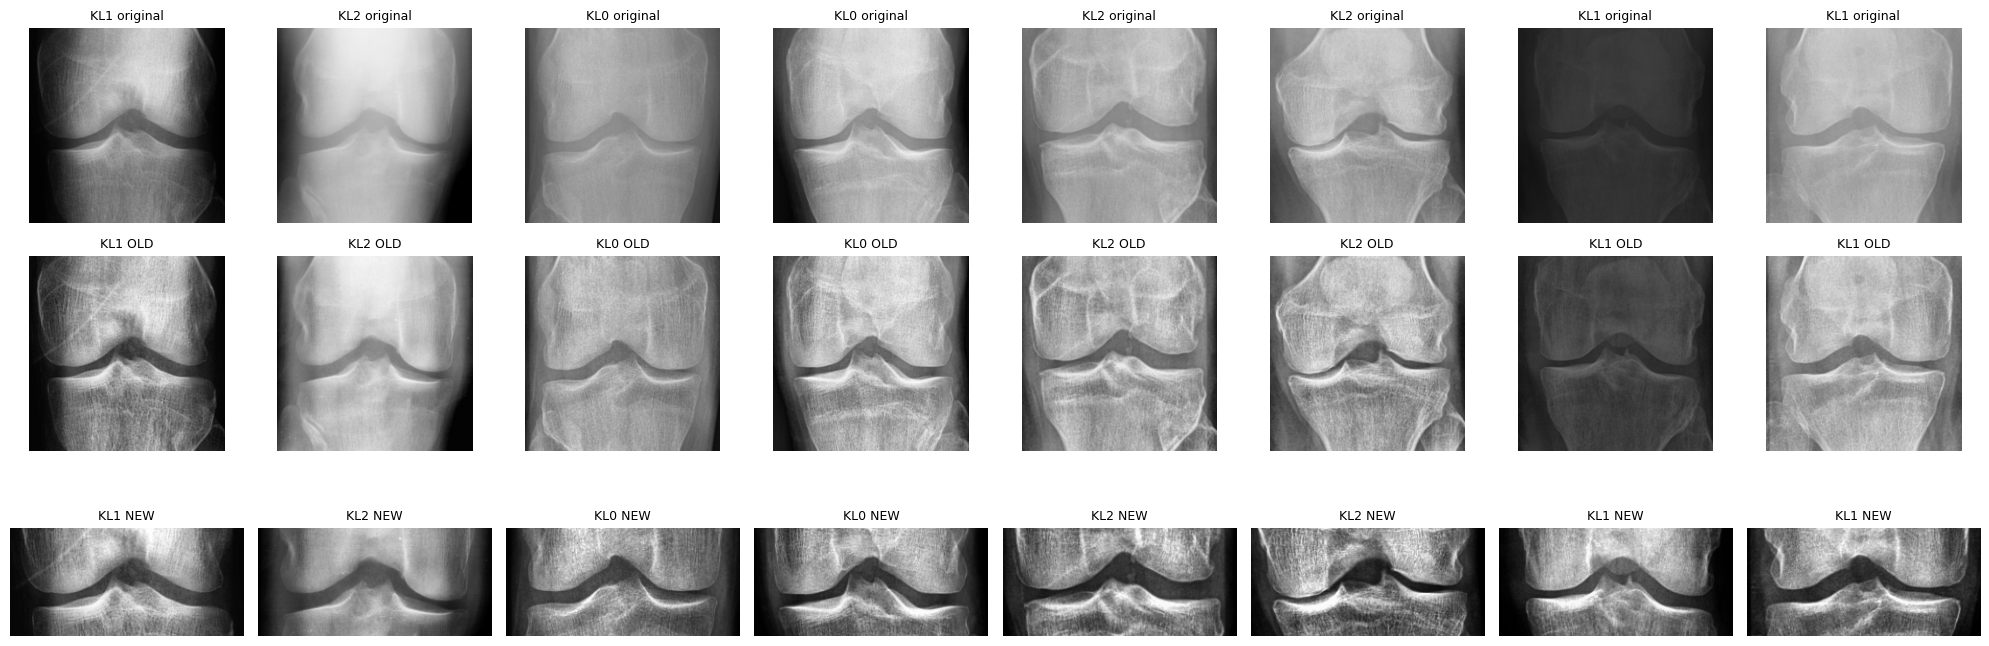

In [10]:
# Look at 8 random images: original | old pipeline | new pipeline
sample = random.Random(0).sample(train.samples, 8)
fig, ax = plt.subplots(3, 8, figsize=(20, 7))
for i, (p, y) in enumerate(sample):
    im = Image.open(p)
    for r, (title, img) in enumerate([("original", im.convert("L")), ("OLD", PRE["old"](im)), ("NEW", PRE["new"](im))]):
        ax[r][i].imshow(img, cmap="gray", vmin=0, vmax=255); ax[r][i].axis("off")
        ax[r][i].set_title(f"KL{y} {title}", fontsize=9)
plt.tight_layout(); plt.show()
PRE["new"].status.clear()


## Check the NEW preprocessing on ALL images (set RUN_VERIFY = False to skip)


In [11]:
# ---------- Thresholds (change here only) ----------
MEAN_TOL      = 6      # output mean brightness must be within TARGET_MEAN +/- this
SAT_ADDED_MAX = 0.03   # max EXTRA fraction of pure black/white pixels created by the processing (natural black borders do not count)
RANGE_MIN     = 110    # min (p99 - p1) of the output = enough contrast
RAW_RANGE_MIN = 40     # original with less contrast than this = noise gets amplified
BLACK_MAX     = 0.25   # original with more than this fraction of black pixels (big empty border)
JOINT_PROM    = 8      # min depth of the joint-gap valley in the OUTPUT (brightness levels)
MARGIN_MIN    = 15     # joint must be at least this many pixels away from the top/bottom of the crop
BLUR_PCT      = 2      # sharpness below this percentile of the dataset = suspicious
MAX_PAGES     = 6      # pages shown per category (25 images per page)


def valley_in_crop(crop):
    """Joint gap inside the final crop: (row, depth) of the strongest dark valley, or (None, 0)."""
    H, W = crop.shape
    prof = gaussian_filter1d(crop[:, int(W * .25):int(W * .75)].astype(np.float32).mean(1), sigma=H * 0.03)
    pk, pr = find_peaks(-prof, prominence=1)                  # interior valleys only (an edge "valley" is not evidence of a joint)
    if len(pk) == 0:
        return None, 0.0
    i = int(np.argmax(pr["prominences"]))
    return int(pk[i]), float(pr["prominences"][i])


def check_one(path):
    im = Image.open(path)
    raw = np.array(im.convert("L").resize((SIZE_STD, SIZE_STD)))
    out_img, status = standardize_std(im)                      # exactly what the model gets
    out = np.array(out_img)
    H = out.shape[0]
    p1, p99 = np.percentile(out, (1, 99))
    r1, r99 = np.percentile(raw, (1, 99))
    row, depth = valley_in_crop(out)
    margin = -1 if row is None else min(row, H - row)
    return dict(
        path=path, status=status, orig_size=f"{im.size[0]}x{im.size[1]}",
        raw_mean=raw.mean(), raw_std=raw.std(), raw_range=r99 - r1, raw_black=(raw < 8).mean(),
        raw_sat=((raw == 0) | (raw == 255)).mean(),
        out_mean=out.mean(), out_std=out.std(), out_range=p99 - p1,
        out_sat=((out == 0) | (out == 255)).mean(),
        sharp=cv2.Laplacian(out, cv2.CV_64F).var(),
        joint_row=row, joint_depth=depth, joint_margin=margin, out_h=H,
    )


  train: 2000/5778
  train: 4000/5778

Images checked: 8260  (train 5778 | val 826 | test 1656)

check                             images      %
[HARD] wrong_size                      0   0.0%
[HARD] brightness_off                  0   0.0%
[HARD] low_contrast                    0   0.0%
[HARD] joint_near_crop_edge            7   0.1%
[soft] saturated (added)             439   5.3%
[soft] noisy_original                 14   0.2%
[soft] blurry                        166   2.0%
[soft] big_black_area                  0   0.0%
[soft] joint_not_found                 2   0.0%
[soft] joint_far_from_usual           18   0.2%
[soft] joint_at_border (cut?)          9   0.1%
[soft] joint_weak_in_crop              6   0.1%
clean (no flag at all)              7616  92.2%

Brightness uniformity (std of mean brightness across images; smaller = more uniform):
  before standardization: 27.3   after: 0.1
Contrast (std of pixel values): spread across images before 14.4 | after 5.0
Pure black/white pixels

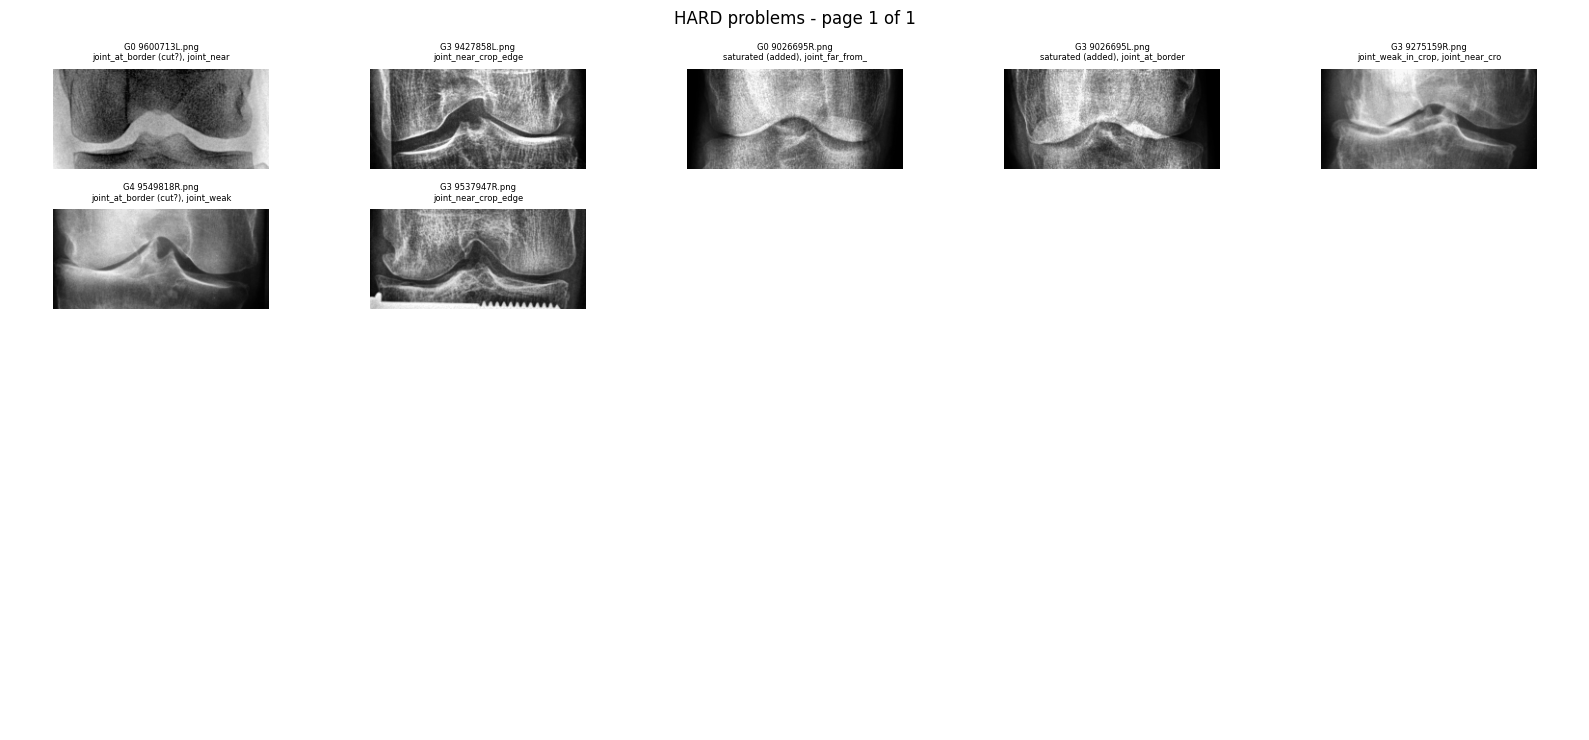

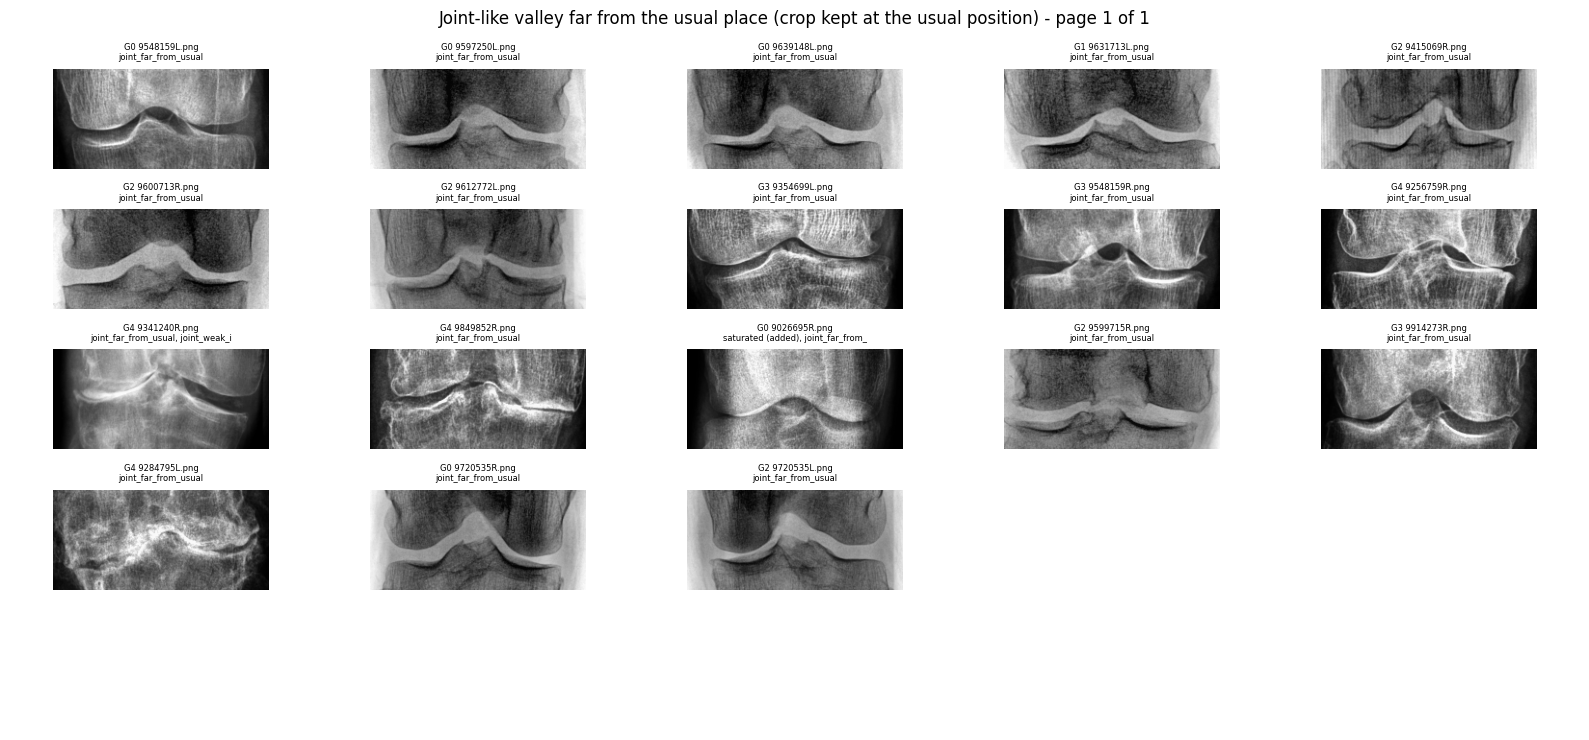

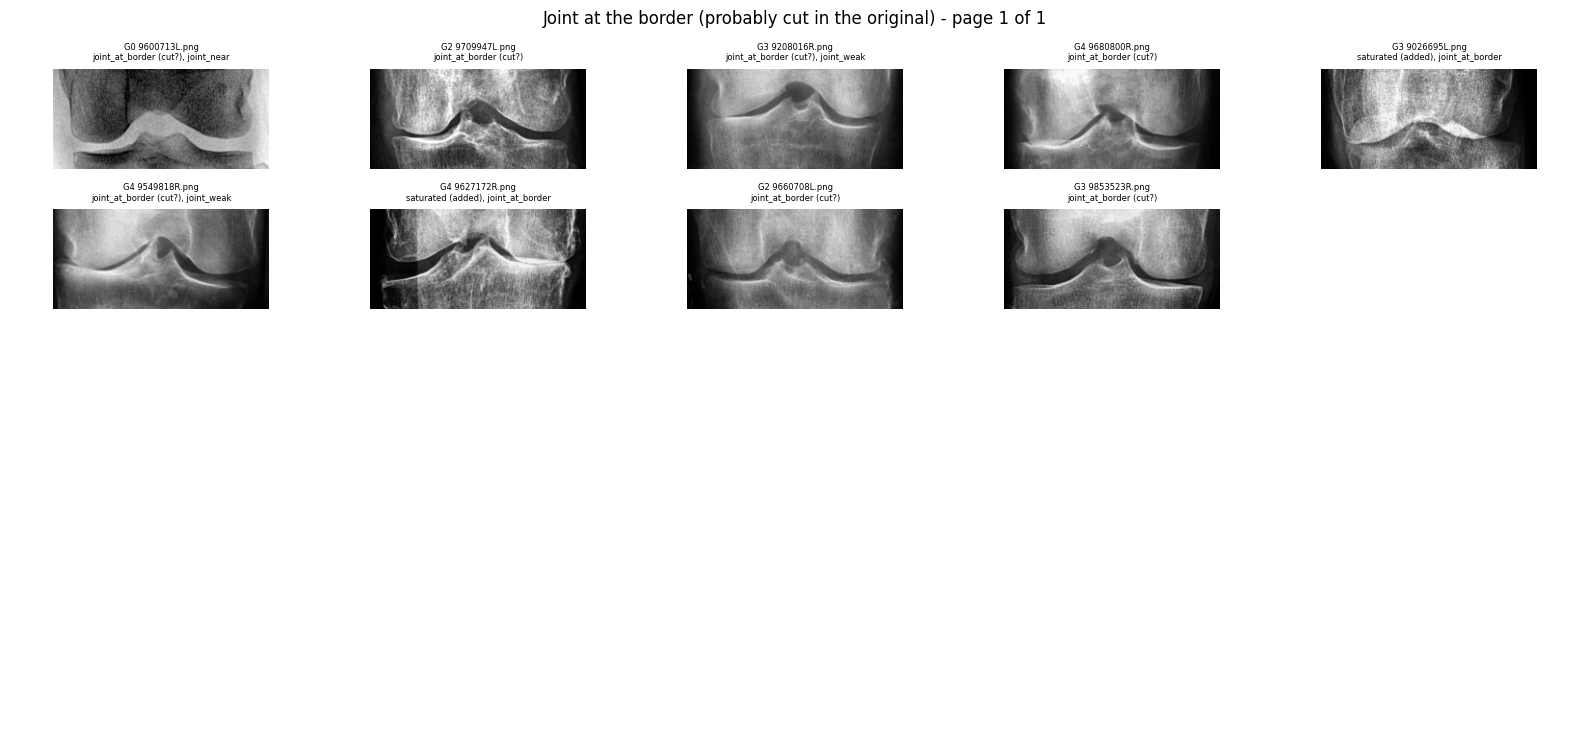

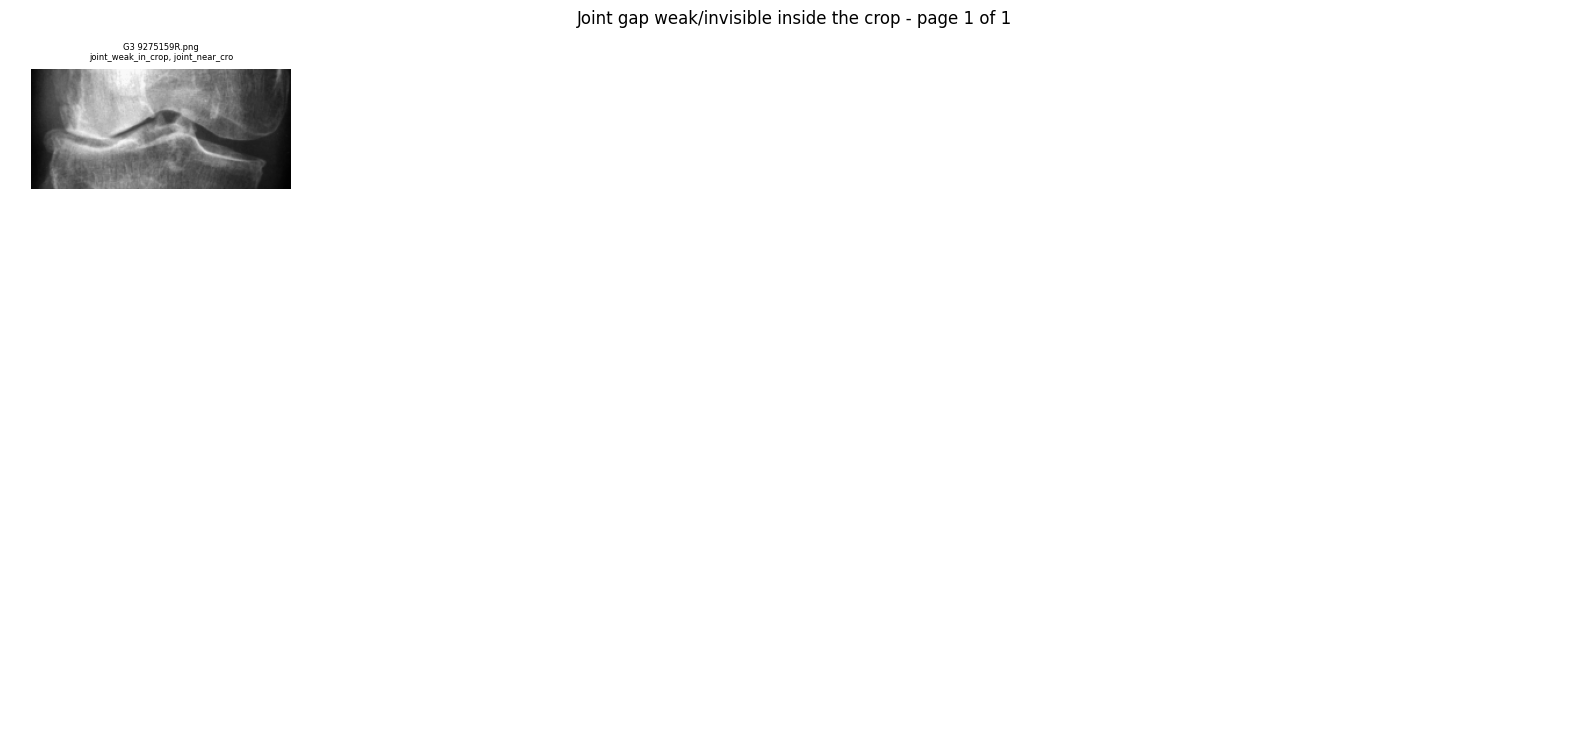

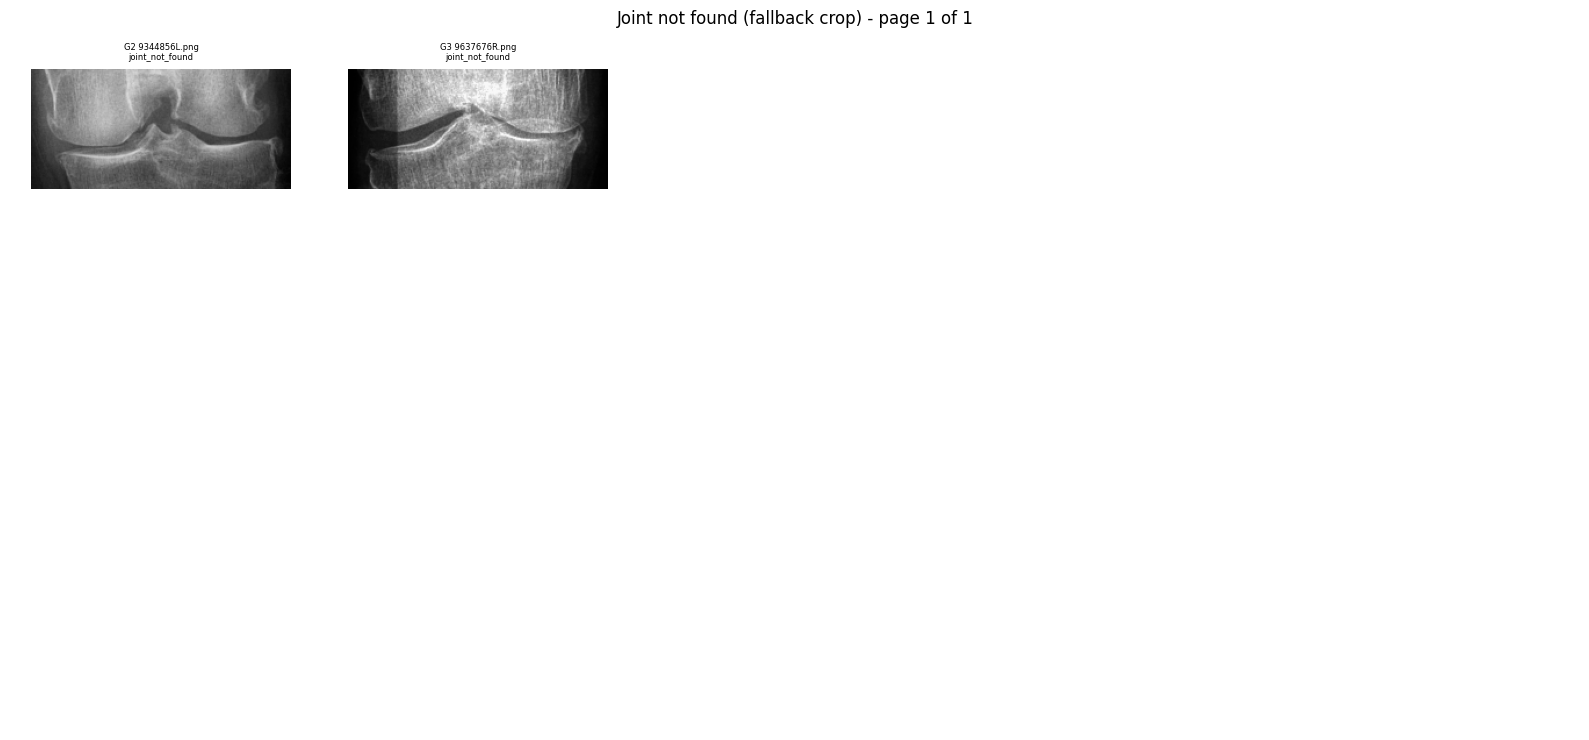

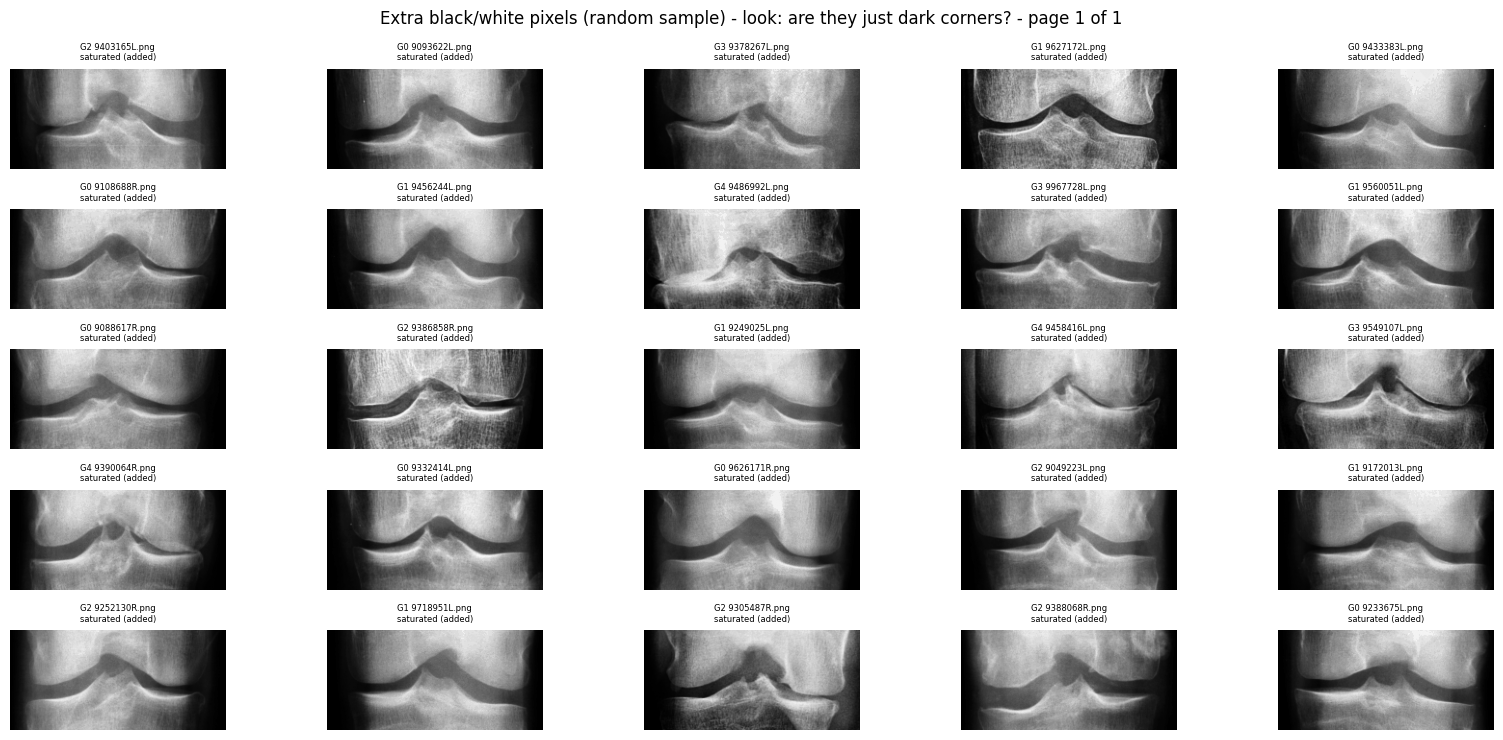

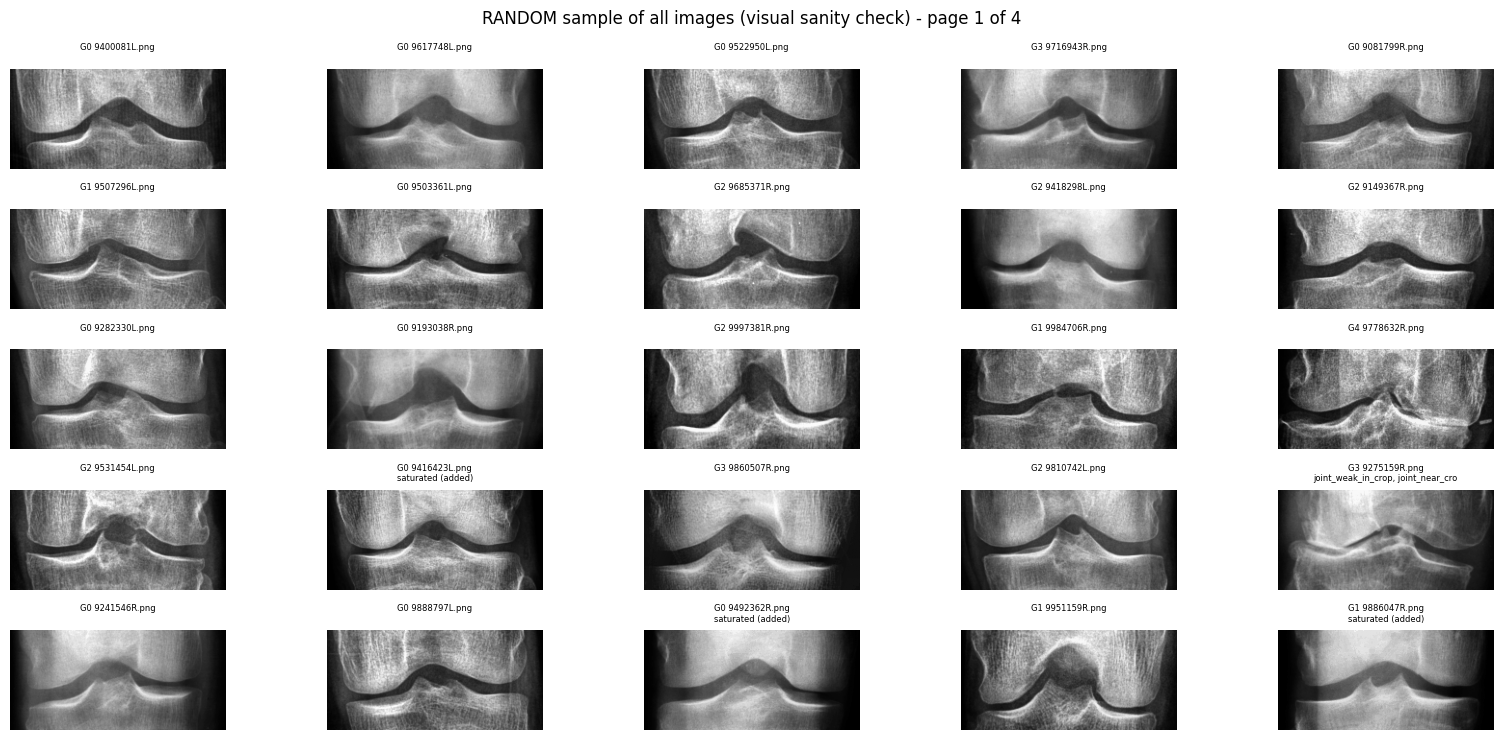

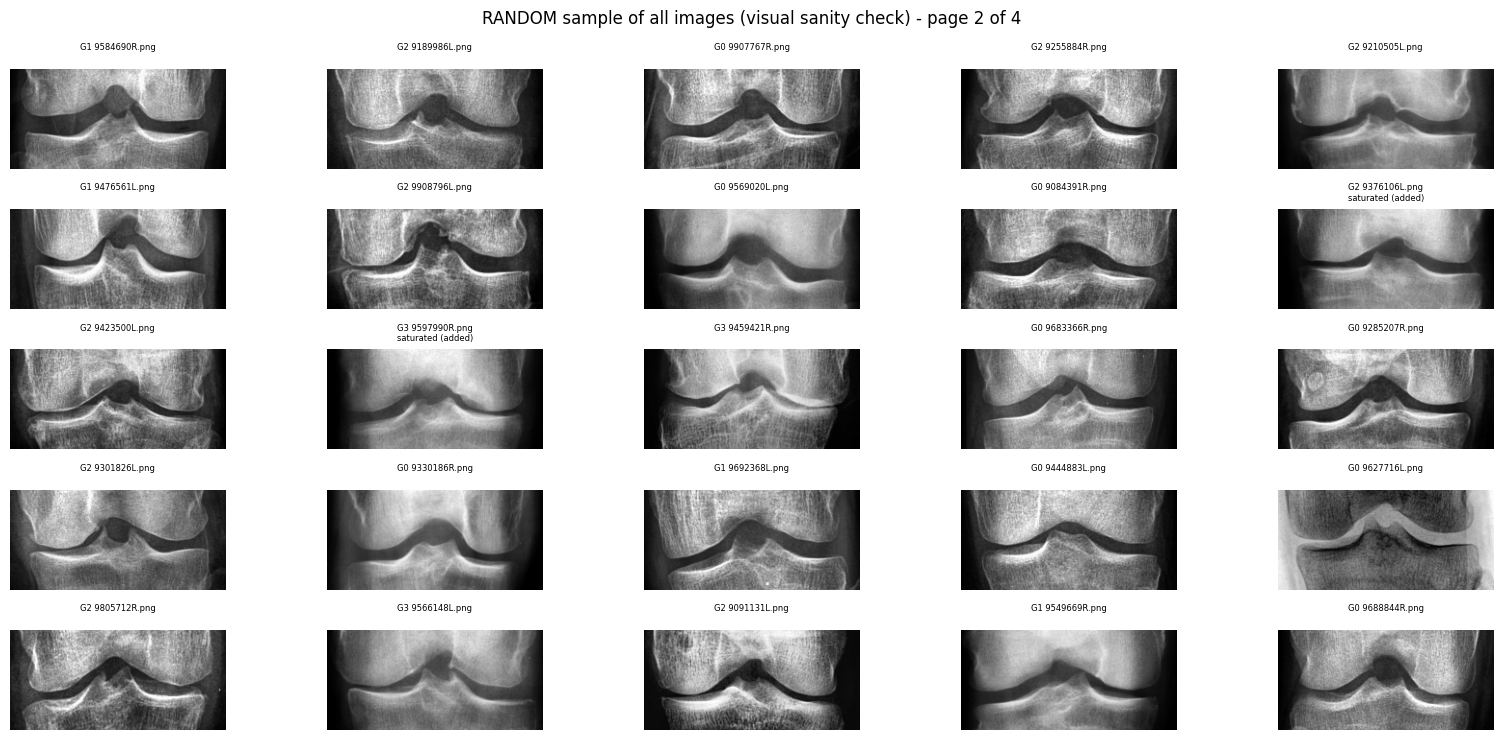

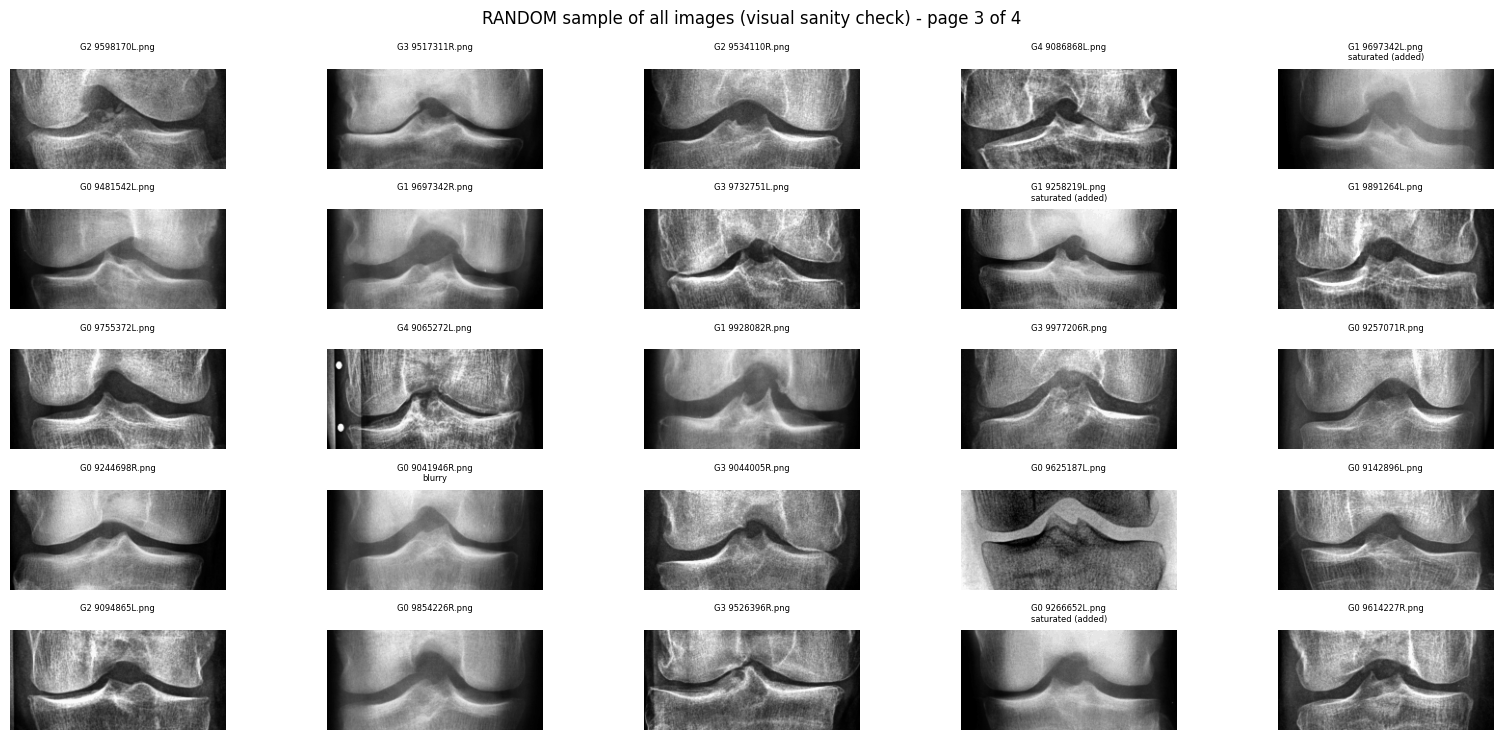

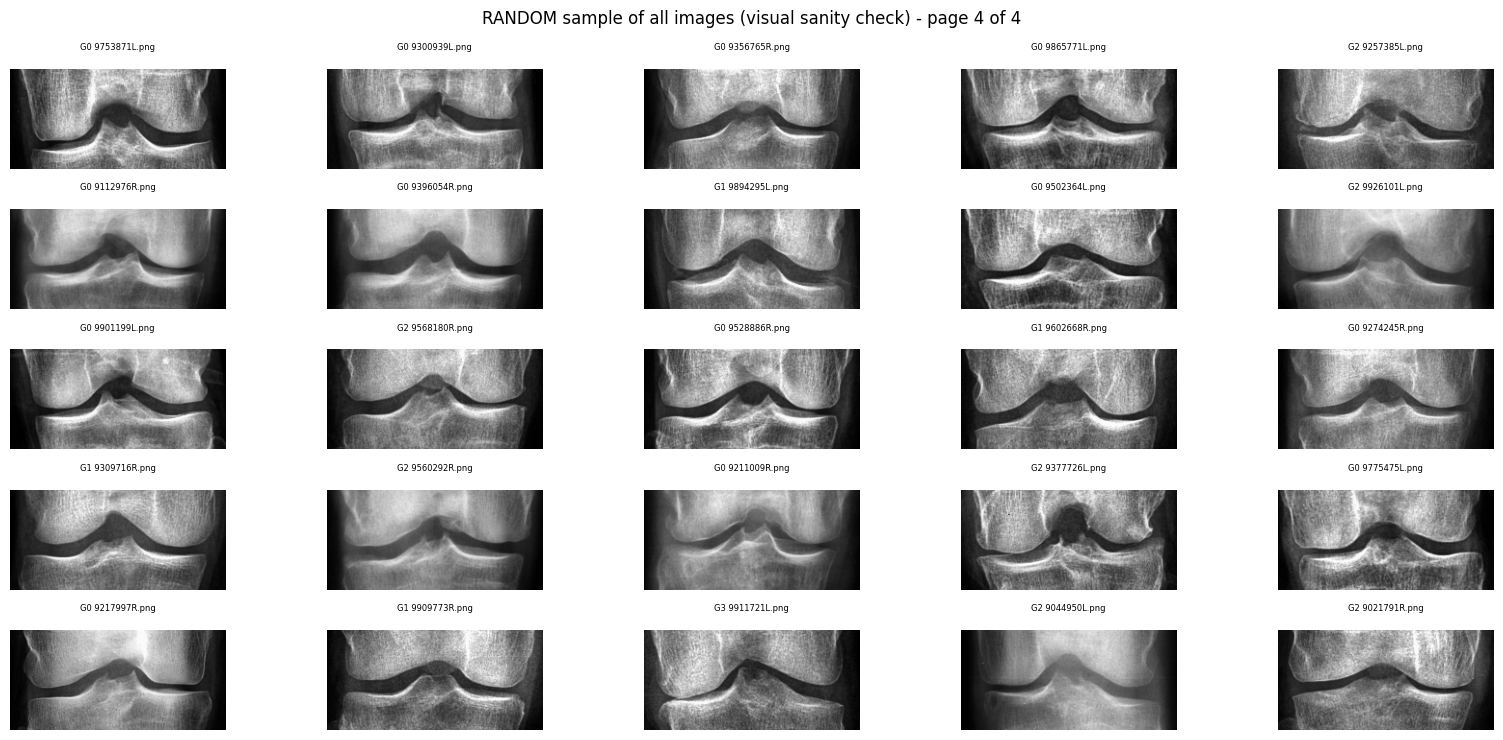


How to read this:
  - HARD must be 0 (or you looked at every image and accepted it).
  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.
  - never remove anything from val/test: the evaluation must stay on the full, untouched set.
  - details per image: standardized_check.csv


In [12]:
if RUN_VERIFY:
    # ---------- 1) Measure every image ----------
    rows = []
    for split, ds in [("train", train), ("val", val), ("test", test)]:
        for k, (p, y) in enumerate(ds.samples):
            d = check_one(p); d.update(split=split, grade=y); rows.append(d)
            if (k + 1) % 2000 == 0:
                print(f"  {split}: {k + 1}/{len(ds.samples)}")
    df = pd.DataFrame(rows)
    sharp_cut = np.percentile(df["sharp"], BLUR_PCT)

    # ---------- 2) Flags (one image can have several) ----------
    FLAGS = {
        "wrong_size":     (df["out_h"] != WINDOW_H_STD) | (df["orig_size"] != f"{SIZE_STD}x{SIZE_STD}"),
        "brightness_off": (df["out_mean"] - TARGET_MEAN).abs() > MEAN_TOL,
        "saturated (added)": (df["out_sat"] - df["raw_sat"]) > SAT_ADDED_MAX,
        "low_contrast":   df["out_range"] < RANGE_MIN,
        "noisy_original": df["raw_range"] < RAW_RANGE_MIN,
        "blurry":         df["sharp"] < sharp_cut,
        "big_black_area": df["raw_black"] > BLACK_MAX,
        "joint_not_found": df["status"] == "fallback",
        "joint_far_from_usual":   df["status"] == "off_center",
        "joint_at_border (cut?)":    df["status"] == "edge",
        "joint_weak_in_crop": df["joint_depth"] < JOINT_PROM,
        "joint_near_crop_edge": (df["joint_margin"] >= 0) & (df["joint_margin"] < MARGIN_MIN),
    }
    for k, v in FLAGS.items():
        df[k] = v
    HARD = ["wrong_size", "brightness_off", "low_contrast", "joint_near_crop_edge"]   # "saturated (added)" is soft: CLAHE + the 1% stretch create some white/black pixels by design
    SOFT = [k for k in FLAGS if k not in HARD]
    df["n_flags"] = df[list(FLAGS)].sum(axis=1)
    df["reasons"] = df[list(FLAGS)].apply(lambda r: ", ".join(k for k in FLAGS if r[k]), axis=1)
    df.drop(columns=list(FLAGS)).to_csv("standardized_check.csv", index=False)

    # ---------- 3) Report ----------
    N = len(df)
    print(f"\nImages checked: {N}  (train {sum(df.split == 'train')} | val {sum(df.split == 'val')} | test {sum(df.split == 'test')})")
    print(f"\n{'check':32s}{'images':>8s}{'%':>7s}")
    for k in HARD + SOFT:
        n = int(df[k].sum()); print(f"{('[HARD] ' if k in HARD else '[soft] ') + k:32s}{n:8d}{100 * n / N:6.1f}%")
    clean = int((df["n_flags"] == 0).sum())
    print(f"{'clean (no flag at all)':32s}{clean:8d}{100 * clean / N:6.1f}%")

    print("\nBrightness uniformity (std of mean brightness across images; smaller = more uniform):")
    print(f"  before standardization: {df.raw_mean.std():.1f}   after: {df.out_mean.std():.1f}")
    print(f"Contrast (std of pixel values): spread across images before {df.raw_std.std():.1f} | after {df.out_std.std():.1f}")
    print(f"Pure black/white pixels: original {100 * df.raw_sat.mean():.1f}% of all pixels | after processing {100 * df.out_sat.mean():.1f}%")
    print("\nMean brightness per grade (should be almost equal after; a gap would let the model cheat on brightness):")
    print(df.groupby("grade")[["raw_mean", "out_mean"]].mean().round(1).to_string())
    print("\nMean brightness per split (train / val / test must look the same):")
    print(df.groupby("split")[["out_mean", "out_std", "sharp"]].mean().round(1).to_string())
    print("\nJoint position inside the crop (rows 0-%d, centre = %d):" % (WINDOW_H_STD, WINDOW_H_STD // 2))
    j = df[df.joint_row.notna()]
    print(f"  median {j.joint_row.median():.0f} | 5th-95th percentile {j.joint_row.quantile(.05):.0f}-{j.joint_row.quantile(.95):.0f}")

    # ---------- 4) Look at the suspicious images (file names in the titles) ----------
    def show(items, title, max_pages=MAX_PAGES):
        items = list(items)
        for pg in range(min(max_pages, -(-len(items) // 25))):
            fig, axes = plt.subplots(5, 5, figsize=(16, 7.5))
            for ax in axes.ravel(): ax.axis("off")
            for ax, (_, r) in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
                ax.imshow(standardize_std(Image.open(r.path))[0], cmap="gray", vmin=0, vmax=255)
                ax.set_title(f"G{r.grade} {r.path.split('/')[-1][:18]}\n{r.reasons[:34]}", fontsize=6)
            fig.suptitle(f"{title} - page {pg + 1} of {-(-len(items) // 25)}")
            plt.tight_layout(); plt.show()

    hard_any = df[df[HARD].any(axis=1)]
    print(f"\nImages with at least one HARD problem: {len(hard_any)}")
    if len(hard_any): show(hard_any.iterrows(), "HARD problems")
    far = df[df["joint_far_from_usual"]]
    if len(far): show(far.iterrows(), "Joint-like valley far from the usual place (crop kept at the usual position)")
    cut = df[df["joint_at_border (cut?)"]]
    if len(cut): show(cut.iterrows(), "Joint at the border (probably cut in the original)")
    weak = df[df["joint_weak_in_crop"] & ~df["joint_at_border (cut?)"] & ~df["joint_far_from_usual"] & ~df["joint_not_found"]]
    if len(weak): show(weak.iterrows(), "Joint gap weak/invisible inside the crop", 3)
    nf = df[df["joint_not_found"]]
    if len(nf): show(nf.iterrows(), "Joint not found (fallback crop)", 2)
    random.seed(0)
    sat_added = df[df["saturated (added)"]]
    if len(sat_added): show(sat_added.sample(min(25, len(sat_added)), random_state=0).iterrows(), "Extra black/white pixels (random sample) - look: are they just dark corners?", 1)
    # 100 random images of ALL images (not only the "clean" ones): if you look at them all and see no problem,
    # the share of bad images is below about 3% (95% confidence, "rule of three")
    show(df.sample(min(100, len(df)), random_state=1).iterrows(), "RANDOM sample of all images (visual sanity check)", 4)

    print("\nHow to read this:")
    print("  - HARD must be 0 (or you looked at every image and accepted it).")
    print("  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.")
    print("  - never remove anything from val/test: the evaluation must stay on the full, untouched set.")
    print("  - details per image: standardized_check.csv")
else:
    print('verification skipped (RUN_VERIFY = False)')


## Datasets and loaders (same augmentation as before; the pipeline decides what is cached)


In [13]:
norm = [transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]

# per-epoch (cheap) part - same as before
tf = transforms.Compose([transforms.Grayscale(3)] + norm)                       # val / test
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
] + norm)

class CachedDS(Dataset):
    """Keeps the pre-processed (1-channel) images in RAM."""
    def __init__(self, base_ds, pre, post):
        self.items = []
        for p, y in base_ds.samples:
            with Image.open(p) as im:
                self.items.append((pre(im), y))
        self.post = post
        self.samples, self.targets = base_ds.samples, base_ds.targets
        self.classes, self.class_to_idx = base_ds.classes, base_ds.class_to_idx
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        img, y = self.items[i]
        return self.post(img), y

def build_loaders(pipeline):
    """Builds train_loader / val_loader / test_loader for 'old' or 'new' (they are global, like before)."""
    global train_loader, val_loader, test_loader
    for name in ("train_loader", "val_loader", "test_loader"):      # free the previous workers
        globals().pop(name, None)
    gc.collect()
    pre = PRE[pipeline]
    def make(split, post):
        ds = datasets.ImageFolder(f"{base}/{split}")
        remap(ds)
        if SMOKE_TEST:
            shrink(ds, SMOKE_N[split])
        return CachedDS(ds, pre, post)
    print(f"Caching pre-processed images for pipeline '{pipeline}' (one time only)...")
    tr, va, te = make("train", train_tf), make("val", tf), make("test", tf)
    train_loader = DataLoader(tr, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
    val_loader   = DataLoader(va, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
    test_loader  = DataLoader(te, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
    images, labels = next(iter(train_loader))
    print("batch shape:", images.shape, "| train:", len(tr), "| val:", len(va), "| test:", len(te))
    if pipeline == "new":
        print("joint detection status (ok / off_center / edge / fallback):", dict(PRE["new"].status))


## Training functions (same code as before)


In [14]:
from sklearn.metrics import f1_score
import time

# Mixed precision (AMP) -> less GPU memory + much faster on T4
use_amp = (device == 'cuda')
FROZEN_BLOCKS = 0   # number of early blocks of model.features kept frozen (set in Phase 2)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_epoch(loader, optimizer=None, freeze_backbone=False):
    """Train one epoch if optimizer is given, otherwise just evaluate.
    Returns (loss, acc%, macro-F1) - F1 is computed in the SAME pass (no 2nd val pass)."""
    training = optimizer is not None
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()              # keep frozen part fully fixed (like Keras)
    elif training and FROZEN_BLOCKS:
        for blk in model.features[:FROZEN_BLOCKS]:
            blk.eval()                     # frozen early blocks: also freeze BatchNorm statistics

    total_loss, correct, n = 0.0, 0, 0
    all_p, all_y = [], []
    with torch.set_grad_enabled(training):
        for i, (x, y) in enumerate(loader):
            if training and i == 5:
                t_s = time.time()          # start timing after warm-up batches
            x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                out = model(x)
                loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            if training and i == 25:
                ips = 20 * loader.batch_size / (time.time() - t_s)
                print(f"   speed: {ips:.0f} img/s -> about {len(loader.dataset) / ips / 60:.1f} min per training epoch")
            pred = out.argmax(1)
            total_loss += loss.item() * len(y)
            correct += (pred == y).sum().item()
            n += len(y)
            if not training:
                all_p.append(pred.cpu()); all_y.append(y.cpu())
    f1 = f1_score(torch.cat(all_y), torch.cat(all_p), average="macro") if not training else float('nan')
    return total_loss / n, 100 * correct / n, f1


In [15]:
def test_report():
    te_loss, te_acc, _ = run_epoch(test_loader)
    print(f"TEST loss {te_loss:.3f} | TEST acc {te_acc:.2f}%")
    model.eval()
    preds, labels = [], []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
        for x, y in test_loader:
            x = x.to(device, memory_format=torch.channels_last)
            preds.extend(model(x).argmax(1).cpu().numpy())
            labels.extend(y.numpy())
    print(classification_report(labels, preds, zero_division=0))
    print(confusion_matrix(labels, preds))


In [16]:
import copy, time

def fit(optimizer, epochs, freeze_backbone, name, scheduler=None, patience=None):
    best_score, best_state, bad = 0, None, 0

    for e in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc, _ = run_epoch(train_loader, optimizer, freeze_backbone)
        va_loss, va_acc, f1 = run_epoch(val_loader)      # one val pass gives loss, acc and F1
        if scheduler is not None:
            scheduler.step()

        if best_state is None or f1 > best_score:
            best_score, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1

        print(f"[{name}] Epoch {e+1:02d}/{epochs} | "
              f"train loss {tr_loss:.3f} acc {tr_acc:.1f} | "
              f"val loss {va_loss:.3f} acc {va_acc:.1f} | "
              f"val F1 {f1:.3f} | {time.time()-t0:.0f}s")

        if patience is not None and bad >= patience:
            print(f"Early stopping (no val-F1 improvement for {patience} epochs)")
            break

    model.load_state_dict(best_state)
    print(f"Restored best epoch (val F1 {best_score:.3f})")


In [17]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def train_one_run(seed, tag=""):
    """The full recipe we used so far (Phase 1 + Phase 2) for ONE seed. Uses the global loaders."""
    global model, FROZEN_BLOCKS, scaler          # run_epoch / fit read these globals
    set_seed(seed)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    # ---- Phase 1: frozen backbone, train only the new classifier ----
    model = models.efficientnet_b5(weights=models.EfficientNet_B5_Weights.DEFAULT)
    for p in model.parameters():
        p.requires_grad = False
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
    model = model.to(device, memory_format=torch.channels_last)
    FROZEN_BLOCKS = 0
    opt1 = optim.Adam(model.classifier.parameters(), lr=0.001)
    fit(opt1, epochs=EPOCHS1, freeze_backbone=True, name=f"{tag}seed {seed} | Phase 1")

    # ---- Phase 2: fine-tune (first 4 blocks frozen), AdamW, warmup + cosine, early stopping ----
    FROZEN_BLOCKS = 4
    for p in model.parameters():
        p.requires_grad = True
    for blk in model.features[:FROZEN_BLOCKS]:
        for p in blk.parameters():
            p.requires_grad = False
    opt2 = optim.AdamW([
        {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": 5e-5},
        {"params": model.classifier.parameters(),                               "lr": 5e-4},
    ], weight_decay=1e-2)
    warm  = optim.lr_scheduler.LinearLR(opt2, start_factor=0.1, total_iters=2)
    cos   = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=max(EPOCHS2 - 2, 1), eta_min=1e-6)
    sched = optim.lr_scheduler.SequentialLR(opt2, [warm, cos], milestones=[2])
    fit(opt2, epochs=EPOCHS2, freeze_backbone=False, name=f"{tag}seed {seed} | Phase 2",
        scheduler=sched, patience=5)             # fit() restores the best-val-F1 epoch


@torch.no_grad()
def predict_probs(loader, tta=True):
    """Class probabilities (with horizontal-flip TTA) for a loader. Same as before."""
    model.eval()
    P, Y = [], []
    for x, y in loader:
        x = x.to(device, memory_format=torch.channels_last)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        P.append(p.cpu()); Y.append(y)
    return torch.cat(P), torch.cat(Y)


## Run: every pipeline x every seed
Each finished run is saved, so if Colab disconnects just run this cell again: finished runs are skipped.


In [18]:
RES = {}      # RES[(pipeline, seed)] = probabilities of that run on val and test
t_all = time.time()
for pipeline in PIPELINES:
    print(f"\n################ PIPELINE: {pipeline} ################")
    todo = [s for s in SEEDS if not os.path.exists(f"{SAVE_DIR}/{pipeline}_seed{s}.npz")]
    if todo:
        build_loaders(pipeline)
    for s in SEEDS:
        f = f"{SAVE_DIR}/{pipeline}_seed{s}.npz"
        if os.path.exists(f):
            print(f"[{pipeline}] seed {s}: already finished, loading saved results")
        else:
            t0 = time.time()
            train_one_run(s, tag=f"{pipeline} | ")
            pv, yv = predict_probs(val_loader)
            pt, yt = predict_probs(test_loader)
            np.savez(f, val=pv.numpy(), yv=yv.numpy(), test=pt.numpy(), yt=yt.numpy())
            torch.save(model.state_dict(), f"{SAVE_DIR}/{pipeline}_seed{s}.pt")
            print(f"[{pipeline}] seed {s} done in {(time.time() - t0) / 60:.1f} min")
            del model
            gc.collect(); torch.cuda.empty_cache()
        RES[(pipeline, s)] = dict(np.load(f))
print(f"\nall runs finished in {(time.time() - t_all) / 60:.1f} min")



################ PIPELINE: old ################
Caching pre-processed images for pipeline 'old' (one time only)...
batch shape: torch.Size([32, 3, 224, 224]) | train: 5778 | val: 826 | test: 1656
Downloading: "https://download.pytorch.org/models/efficientnet_b5_lukemelas-1a07897c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b5_lukemelas-1a07897c.pth


100%|██████████| 117M/117M [00:01<00:00, 118MB/s]


   speed: 289 img/s -> about 0.3 min per training epoch
[old | seed 42 | Phase 1] Epoch 01/3 | train loss 1.684 acc 27.0 | val loss 1.815 acc 27.4 | val F1 0.210 | 39s
   speed: 206 img/s -> about 0.5 min per training epoch
[old | seed 42 | Phase 1] Epoch 02/3 | train loss 1.635 acc 32.1 | val loss 1.778 acc 43.8 | val F1 0.345 | 25s
   speed: 190 img/s -> about 0.5 min per training epoch
[old | seed 42 | Phase 1] Epoch 03/3 | train loss 1.601 acc 33.0 | val loss 1.757 acc 48.3 | val F1 0.402 | 25s
Restored best epoch (val F1 0.402)
   speed: 143 img/s -> about 0.7 min per training epoch
[old | seed 42 | Phase 2] Epoch 01/20 | train loss 1.761 acc 24.6 | val loss 1.819 acc 39.5 | val F1 0.335 | 63s
   speed: 186 img/s -> about 0.5 min per training epoch
[old | seed 42 | Phase 2] Epoch 02/20 | train loss 1.631 acc 32.0 | val loss 1.725 acc 48.5 | val F1 0.425 | 36s
   speed: 177 img/s -> about 0.5 min per training epoch
[old | seed 42 | Phase 2] Epoch 03/20 | train loss 1.467 acc 44.5 |

## Results


In [19]:
# ---------- progressive elimination (coarse -> fine) ----------
def eliminate(p, widths=(3, 2, 1), trace=False):
    """p = probabilities of the grades. Start with all grades; at every stage keep only the block of
    neighbouring grades that holds the most probability and drop the rest:
    5 grades -> best block of 3 -> best block of 2 -> best single grade.
    Example, true grade 1:  {0,1,2,3,4} -> {0,1,2} (3 and 4 out) -> {0,1} (2 out) -> 1."""
    lo, hi = 0, len(p) - 1
    path = [(lo, hi)]
    for w in widths:
        if hi - lo + 1 <= w:
            continue
        s = max(range(lo, hi - w + 2), key=lambda a: p[a:a + w].sum())   # ties -> the lower block
        lo, hi = s, s + w - 1
        path.append((lo, hi))
    return (lo, path) if trace else lo

def decode_all(P):
    return np.array([eliminate(r) for r in P])

def sc(y, pred):
    return dict(acc=100 * (pred == y).mean(), qwk=cohen_kappa_score(y, pred, weights='quadratic'),
                f1=f1_score(y, pred, average='macro'))

first = RES[(PIPELINES[0], SEEDS[0])]
yv, yt = first['yv'], first['yt']
for k, r in RES.items():                       # all runs must use the same images in the same order
    assert (r['yv'] == yv).all() and (r['yt'] == yt).all(), "label order differs between runs"

# ---------- 1) every single run (argmax) ----------
rows = []
for p in PIPELINES:
    for s in SEEDS:
        r = RES[(p, s)]
        v, t = sc(yv, r['val'].argmax(1)), sc(yt, r['test'].argmax(1))
        rows.append(dict(pipeline=p, seed=s, val_qwk=v['qwk'], val_f1=v['f1'],
                         test_acc=t['acc'], test_qwk=t['qwk'], test_f1=t['f1']))
runs = pd.DataFrame(rows)
print("EVERY RUN (argmax, with flip TTA):")
print(runs.round(4).to_string(index=False))

print("\nMEAN +/- STD over seeds (this is the real, honest number):")
for p in PIPELINES:
    d = runs[runs.pipeline == p]
    print(f"  {p:4s} | test acc {d.test_acc.mean():.2f} +/- {d.test_acc.std(ddof=0):.2f} | "
          f"test QWK {d.test_qwk.mean():.4f} +/- {d.test_qwk.std(ddof=0):.4f} | "
          f"test macro-F1 {d.test_f1.mean():.3f} +/- {d.test_f1.std(ddof=0):.3f}")

# ---------- 2) seed ensemble (average of the probabilities) x decoding ----------
ENS, table = {}, []
for p in PIPELINES:
    Pv = np.mean([RES[(p, s)]['val']  for s in SEEDS], 0)
    Pt = np.mean([RES[(p, s)]['test'] for s in SEEDS], 0)
    ENS[p] = (Pv, Pt)
    for dec, fn in [("argmax", lambda P: P.argmax(1)), ("elimination", decode_all)]:
        v, t = sc(yv, fn(Pv)), sc(yt, fn(Pt))
        table.append(dict(pipeline=p, decoding=dec, val_qwk=v['qwk'], val_f1=v['f1'],
                          test_acc=t['acc'], test_qwk=t['qwk'], test_f1=t['f1']))
ens = pd.DataFrame(table)
print("\nSEED ENSEMBLE:")
print(ens.round(4).to_string(index=False))

# ---------- 3) choose on VALIDATION only (the test set is never used to choose) ----------
best = ens.sort_values("val_qwk", ascending=False, kind="stable").iloc[0]
best_pipeline, best_decoding = best.pipeline, best.decoding
print(f"\nChosen on validation QWK: pipeline = '{best_pipeline}', decoding = '{best_decoding}'")

if len(PIPELINES) == 2 and len(SEEDS) > 1:
    a, b = PIPELINES
    da, db = runs[runs.pipeline == a].test_qwk, runs[runs.pipeline == b].test_qwk
    diff, noise = db.mean() - da.mean(), max(da.std(ddof=0), db.std(ddof=0))
    verdict = "WITHIN the seed-to-seed noise -> no reliable difference" if abs(diff) <= noise else "larger than the seed-to-seed noise"
    print(f"Test QWK, mean({b}) - mean({a}) = {diff:+.4f}; seed-to-seed std = {noise:.4f} -> {verdict}")


EVERY RUN (argmax, with flip TTA):
pipeline  seed  val_qwk  val_f1  test_acc  test_qwk  test_f1
     old    42   0.7458  0.6358   64.7343    0.8057   0.6476
     old   123   0.7468  0.6531   63.0435    0.7954   0.6557
     old  2024   0.7549  0.6411   64.4928    0.8017   0.6720
     new    42   0.7612  0.6455   64.2512    0.8076   0.6685
     new   123   0.7512  0.6203   63.4058    0.8134   0.6718
     new  2024   0.7566  0.6185   62.5604    0.8032   0.6558

MEAN +/- STD over seeds (this is the real, honest number):
  old  | test acc 64.09 +/- 0.75 | test QWK 0.8009 +/- 0.0042 | test macro-F1 0.658 +/- 0.010
  new  | test acc 63.41 +/- 0.69 | test QWK 0.8080 +/- 0.0042 | test macro-F1 0.665 +/- 0.007

SEED ENSEMBLE:
pipeline    decoding  val_qwk  val_f1  test_acc  test_qwk  test_f1
     old      argmax   0.7454  0.6403   65.8213    0.8142   0.6737
     old elimination   0.7454  0.6403   65.8213    0.8142   0.6737
     new      argmax   0.7524  0.6300   63.7681    0.8140   0.6702
     n

FINAL: pipeline 'new' | 3-seed ensemble | decoding 'argmax'
test accuracy 63.77% | QWK 0.8140

              precision    recall  f1-score   support

         KL0       0.76      0.73      0.74       639
         KL1       0.32      0.46      0.38       296
         KL2       0.70      0.49      0.58       447
         KL3       0.76      0.83      0.80       223
         KL4       0.81      0.90      0.85        51

    accuracy                           0.64      1656
   macro avg       0.67      0.68      0.67      1656
weighted avg       0.67      0.64      0.64      1656



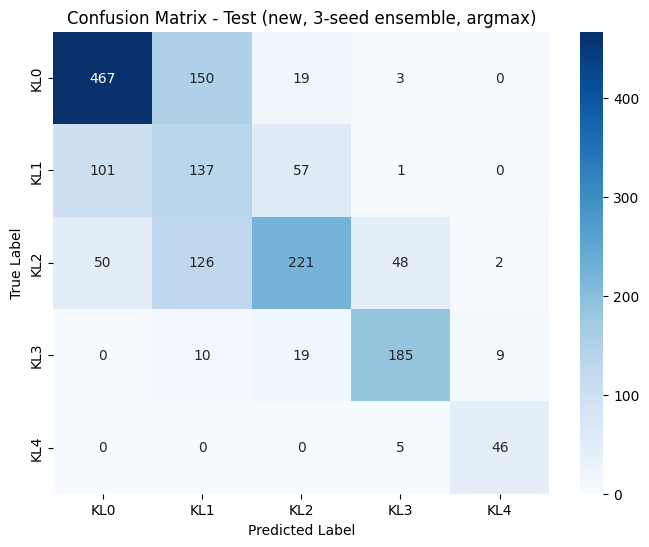

Elimination examples (true grade -> candidate grades after each stage):
  true KL0: {0,1,2,3,4} -> {0,1,2} -> {0,1} -> {0}  => KL0
  true KL2: {0,1,2,3,4} -> {0,1,2} -> {1,2} -> {1}  => KL1
  true KL1: {0,1,2,3,4} -> {0,1,2} -> {0,1} -> {1}  => KL1
  true KL0: {0,1,2,3,4} -> {0,1,2} -> {0,1} -> {0}  => KL0
  true KL0: {0,1,2,3,4} -> {0,1,2} -> {0,1} -> {1}  => KL1
  true KL3: {0,1,2,3,4} -> {2,3,4} -> {3,4} -> {3}  => KL3

Saved in /content/runs: per-run probabilities (.npz), model weights (.pt), final ensemble probabilities (.npy)


In [20]:
# ---------- final report of the chosen configuration ----------
Pv, Pt = ENS[best_pipeline]
final_pred = decode_all(Pt) if best_decoding == "elimination" else Pt.argmax(1)
print(f"FINAL: pipeline '{best_pipeline}' | {len(SEEDS)}-seed ensemble | decoding '{best_decoding}'")
print(f"test accuracy {100 * (final_pred == yt).mean():.2f}% | QWK {cohen_kappa_score(yt, final_pred, weights='quadratic'):.4f}\n")
print(classification_report(yt, final_pred, target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(yt, final_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Confusion Matrix - Test ({best_pipeline}, {len(SEEDS)}-seed ensemble, {best_decoding})')
plt.ylabel('True Label'); plt.xlabel('Predicted Label'); plt.show()

# how the candidate grades shrink for a few test images
print("Elimination examples (true grade -> candidate grades after each stage):")
rng = np.random.default_rng(0)
for i in rng.choice(len(yt), min(6, len(yt)), replace=False):
    g, path = eliminate(Pt[i], trace=True)
    steps = " -> ".join("{" + ",".join(map(str, range(a, b + 1))) + "}" for a, b in path)
    print(f"  true KL{yt[i]}: {steps}  => KL{g}")

np.save(f"{SAVE_DIR}/final_ensemble_test_probs_{best_pipeline}.npy", Pt)
print(f"\nSaved in {SAVE_DIR}: per-run probabilities (.npz), model weights (.pt), final ensemble probabilities (.npy)")
if SMOKE_TEST:
    print("REMINDER: this was only the SMOKE TEST. Set SMOKE_TEST = False and run again for real results.")
